<a href="https://colab.research.google.com/github/tsegaye12-bir/PhD-Dessertation-/blob/main/Optimized_paper_in_public_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# %% Cell 1: Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

import os
DRIVE_ROOT = '/content/drive/MyDrive'
ZIP_PATH = os.path.join(DRIVE_ROOT, 'Datasets.zip')
print('Zip exists:', os.path.exists(ZIP_PATH))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Zip exists: True


In [6]:
# %% Cell 2: Unzip the dataset from Drive
import zipfile, os, shutil

EXTRACT_ROOT = '/content/datasets'
os.makedirs(EXTRACT_ROOT, exist_ok=True)

if not any(os.scandir(EXTRACT_ROOT)):
    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        z.extractall(EXTRACT_ROOT)
    print('Extracted to', EXTRACT_ROOT)
else:
    print('Already extracted')

# Print top-level structure (up to 2 levels deep)
for root, dirs, files in os.walk(EXTRACT_ROOT):
    depth = root.replace(EXTRACT_ROOT, '').count(os.sep)
    if depth > 1:
        dirs[:] = []
        continue
    print('  ' * depth + os.path.basename(root) + '/')
    if depth == 1:
        print('  ' * (depth + 1) + f'[{len(files)} files, {len(dirs)} subfolders]')

Already extracted
datasets/
  Datasets/
    [0 files, 4 subfolders]


In [7]:
# %% Cell 3: Imports and global config
import os, re, time, json, random, math, copy
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, cohen_kappa_score)
from scipy.stats import chi2 as chi2_dist
from tqdm.auto import tqdm

# ---------------- Global configuration (matches manuscript) ----------------
CONFIG = dict(
    img_size=224,
    batch_size=32,
    num_workers=2,
    epochs=50,
    warmup_epochs=5,
    lr=1e-4,
    weight_decay=1e-4,
    seeds=[42, 123, 2024],       # manuscript: three-seed repeated runs
    primary_seed=42,
    cutmix_prob=0.3,             # manuscript: CutMix p = 0.3
    cutmix_alpha=1.0,
    num_classes=14,
    label_smoothing=0.0,
)
CKPT_DIR = os.path.join(DRIVE_ROOT, 'cropxnet_checkpoints')
os.makedirs(CKPT_DIR, exist_ok=True)
RESULTS_DIR = os.path.join(DRIVE_ROOT, 'cropxnet_results')
os.makedirs(RESULTS_DIR, exist_ok=True)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE == 'cuda' else '')

def set_seed(seed: int):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(CONFIG['primary_seed'])

Device: cuda Tesla T4


In [8]:
# %% Cell 4: Discover classes and build a path/label DataFrame
# Manuscript class labels and expected total source-image counts
EXPECTED_CLASSES = {
    'Coffee_Leaf_Rust':            8336,
    'Coffee_Cercospora':           7681,
    'Coffee_Healthy':             18983,
    'Coffee_Miner':               17000,
    'Coffee_Phoma':                6571,
    'Maize_Common_Rust':           1907,
    'Maize_Northern_Leaf_Blight':  1908,
    'Maize_Healthy':               1859,
    'Maize_Gray_Leaf_Spot':        1642,
    'Pepper_Bacterial_Spot':        997,
    'Pepper_Healthy':              1478,
    'Wheat_Septoria':                97,
    'Wheat_Stripe_Rust':            208,
    'Wheat_Healthy':                102,
}
CLASS_NAMES = sorted(EXPECTED_CLASSES.keys())
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASS_NAMES)}
print('Classes:', CLASS_NAMES)

# Robust folder-name → canonical class mapping
ALIASES = {
    'coffee_leaf_rust': 'Coffee_Leaf_Rust',
    'coffee_rust': 'Coffee_Leaf_Rust',
    'coffee_cercospora': 'Coffee_Cercospora',
    'coffee_healthy': 'Coffee_Healthy',
    'coffee_miner': 'Coffee_Miner',
    'coffee_leaf_miner': 'Coffee_Miner',
    'coffee_phoma': 'Coffee_Phoma',
    'maize_common_rust': 'Maize_Common_Rust',
    'corn_common_rust': 'Maize_Common_Rust',
    'maize_northern_leaf_blight': 'Maize_Northern_Leaf_Blight',
    'corn_northern_leaf_blight': 'Maize_Northern_Leaf_Blight',
    'maize_healthy': 'Maize_Healthy',
    'corn_healthy': 'Maize_Healthy',
    'maize_gray_leaf_spot': 'Maize_Gray_Leaf_Spot',
    'corn_gray_leaf_spot': 'Maize_Gray_Leaf_Spot',
    'corn_cercospora_gray_leaf_spot': 'Maize_Gray_Leaf_Spot',
    'pepper_bacterial_spot': 'Pepper_Bacterial_Spot',
    'pepper_bell_bacterial_spot': 'Pepper_Bacterial_Spot',
    'pepper_healthy': 'Pepper_Healthy',
    'pepper_bell_healthy': 'Pepper_Healthy',
    'wheat_septoria': 'Wheat_Septoria',
    'wheat_stripe_rust': 'Wheat_Stripe_Rust',
    'wheat_healthy': 'Wheat_Healthy',
}

def normalize(name: str) -> str:
    s = name.lower().strip()
    s = re.sub(r'[\s\-\.\,\(\)]+', '_', s)
    s = re.sub(r'_{2,}', '_', s).strip('_')
    # Remove common prefixes like "coffee___" → "coffee_"
    return s

IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.JPG', '.JPEG', '.PNG'}

records = []
unmatched = defaultdict(int)
for root, dirs, files in os.walk(EXTRACT_ROOT):
    # Only treat leaf folders as class folders
    imgs = [f for f in files if os.path.splitext(f)[1] in IMG_EXTS]
    if len(imgs) == 0:
        continue
    folder_norm = normalize(os.path.basename(root))
    # Try alias, then direct match
    canonical = ALIASES.get(folder_norm)
    if canonical is None:
        # try partial matching against any alias key
        for k, v in ALIASES.items():
            if k in folder_norm or folder_norm in k:
                canonical = v; break
    if canonical is None:
        unmatched[os.path.basename(root)] += len(imgs)
        continue
    for f in imgs:
        records.append((os.path.join(root, f), canonical))

df = pd.DataFrame(records, columns=['path', 'label'])
print('Total images found:', len(df))
print('\nPer-class counts:\n', df['label'].value_counts().sort_index())
if unmatched:
    print('\nUnmatched folders (ignored):', dict(unmatched))

# Sanity-check against manuscript totals
for c in CLASS_NAMES:
    got = (df['label'] == c).sum()
    exp = EXPECTED_CLASSES[c]
    flag = 'OK' if abs(got - exp) <= max(5, 0.02 * exp) else 'MISMATCH'
    print(f'{c:35s} found={got:6d} expected={exp:6d} {flag}')

Classes: ['Coffee_Cercospora', 'Coffee_Healthy', 'Coffee_Leaf_Rust', 'Coffee_Miner', 'Coffee_Phoma', 'Maize_Common_Rust', 'Maize_Gray_Leaf_Spot', 'Maize_Healthy', 'Maize_Northern_Leaf_Blight', 'Pepper_Bacterial_Spot', 'Pepper_Healthy', 'Wheat_Healthy', 'Wheat_Septoria', 'Wheat_Stripe_Rust']
Total images found: 46852

Per-class counts:
 label
Coffee_Healthy                19085
Coffee_Leaf_Rust               8336
Coffee_Miner                  10978
Maize_Common_Rust              1907
Maize_Healthy                  1859
Maize_Northern_Leaf_Blight     1908
Pepper_Bacterial_Spot           997
Pepper_Healthy                 1478
Wheat_Septoria                   97
Wheat_Stripe_Rust               207
Name: count, dtype: int64

Unmatched folders (ignored): {'Cerscospora': 7681, 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot': 1642}
Coffee_Cercospora                   found=     0 expected=  7681 MISMATCH
Coffee_Healthy                      found= 19085 expected= 18983 OK
Coffee_Leaf_Rust

In [9]:
# %% Cell 5: Create deterministic stratified splits with exact test/val counts
# Manuscript Table 1 exact split sizes
SPLIT_COUNTS = {
    #  class:                          (train, val, test)
    'Coffee_Leaf_Rust':               (5835, 1250, 1251),
    'Coffee_Cercospora':              (5377, 1152, 1152),
    'Coffee_Healthy':                 (13288, 2847, 2848),
    'Coffee_Miner':                   (11900, 2550, 2550),
    'Coffee_Phoma':                   (4600, 985, 986),
    'Maize_Common_Rust':              (1335, 286, 286),
    'Maize_Northern_Leaf_Blight':     (1336, 286, 286),
    'Maize_Healthy':                  (1301, 279, 279),
    'Maize_Gray_Leaf_Spot':           (1149, 246, 247),
    'Pepper_Bacterial_Spot':          (698, 150, 149),
    'Pepper_Healthy':                 (1035, 222, 221),
    'Wheat_Septoria':                 (68, 15, 14),
    'Wheat_Stripe_Rust':              (146, 31, 31),
    'Wheat_Healthy':                  (71, 15, 16),
}

SPLITS_CSV = os.path.join(RESULTS_DIR, 'splits.csv')

def make_splits(seed=42):
    rng = np.random.RandomState(seed)
    rows = []
    for cls, (ntr, nva, nte) in SPLIT_COUNTS.items():
        cls_df = df[df['label'] == cls].sample(frac=1.0, random_state=seed).reset_index(drop=True)
        n = len(cls_df)
        if ntr + nva + nte > n:
            # rescale proportionally if data is short
            scale = n / (ntr + nva + nte)
            ntr = int(round(ntr * scale))
            nva = int(round(nva * scale))
            nte = n - ntr - nva
        idx_train = cls_df.index[:ntr]
        idx_val   = cls_df.index[ntr:ntr+nva]
        idx_test  = cls_df.index[ntr+nva:ntr+nva+nte]
        for idx, split in [(idx_train, 'train'), (idx_val, 'val'), (idx_test, 'test')]:
            for i in idx:
                rows.append((cls_df.loc[i, 'path'], cls, split))
    return pd.DataFrame(rows, columns=['path', 'label', 'split'])

if os.path.exists(SPLITS_CSV):
    splits_df = pd.read_csv(SPLITS_CSV)
    print('Loaded existing splits from', SPLITS_CSV)
else:
    splits_df = make_splits(CONFIG['primary_seed'])
    splits_df.to_csv(SPLITS_CSV, index=False)
    print('Saved splits to', SPLITS_CSV)

# Report counts
pivot = splits_df.groupby(['label', 'split']).size().unstack(fill_value=0)
print(pivot)
print('\nSplit totals:', splits_df['split'].value_counts().to_dict())

# Save class list for later
with open(os.path.join(RESULTS_DIR, 'class_names.json'), 'w') as f:
    json.dump(CLASS_NAMES, f)

Loaded existing splits from /content/drive/MyDrive/cropxnet_results/splits.csv
split                       test  train   val
label                                        
Coffee_Healthy              2848  13288  2847
Coffee_Leaf_Rust            1251   5835  1250
Coffee_Miner                1646   7685  1647
Maize_Common_Rust            286   1335   286
Maize_Healthy                279   1301   279
Maize_Northern_Leaf_Blight   286   1336   286
Pepper_Bacterial_Spot        149    698   150
Pepper_Healthy               221   1035   222
Wheat_Septoria                14     68    15
Wheat_Stripe_Rust             31    145    31

Split totals: {'train': 32726, 'val': 7013, 'test': 7011}


In [10]:
# %% Cell 6: Dataset, transforms, CutMix
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_tf = T.Compose([
    T.RandomResizedCrop(CONFIG['img_size'], scale=(0.7, 1.0)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees=20),
    T.ColorJitter(brightness=(0.7, 1.3)),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_tf = T.Compose([
    T.Resize((CONFIG['img_size'], CONFIG['img_size'])),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class LeafDataset(Dataset):
    def __init__(self, df, transform):
        self.paths = df['path'].tolist()
        self.labels = df['label'].map(CLASS_TO_IDX).astype(int).tolist()
        self.transform = transform
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert('RGB')
        return self.transform(img), self.labels[i]

def cutmix_batch(x, y, alpha=1.0, prob=0.3):
    """Manuscript: CutMix with mixing probability 0.3, alpha=1.0."""
    if np.random.rand() > prob:
        return x, y, y, 1.0
    lam = np.random.beta(alpha, alpha)
    B, C, H, W = x.shape
    rand_idx = torch.randperm(B, device=x.device)
    cut_rat = np.sqrt(1 - lam)
    cut_w = int(W * cut_rat); cut_h = int(H * cut_rat)
    cx = np.random.randint(W); cy = np.random.randint(H)
    x1 = np.clip(cx - cut_w // 2, 0, W); x2 = np.clip(cx + cut_w // 2, 0, W)
    y1 = np.clip(cy - cut_h // 2, 0, H); y2 = np.clip(cy + cut_h // 2, 0, H)
    x[:, :, y1:y2, x1:x2] = x[rand_idx, :, y1:y2, x1:x2]
    lam = 1 - ((x2 - x1) * (y2 - y1) / (W * H))
    return x, y, y[rand_idx], lam

### Visualizing Preprocessing: Segmentation and CutMix Augmentation

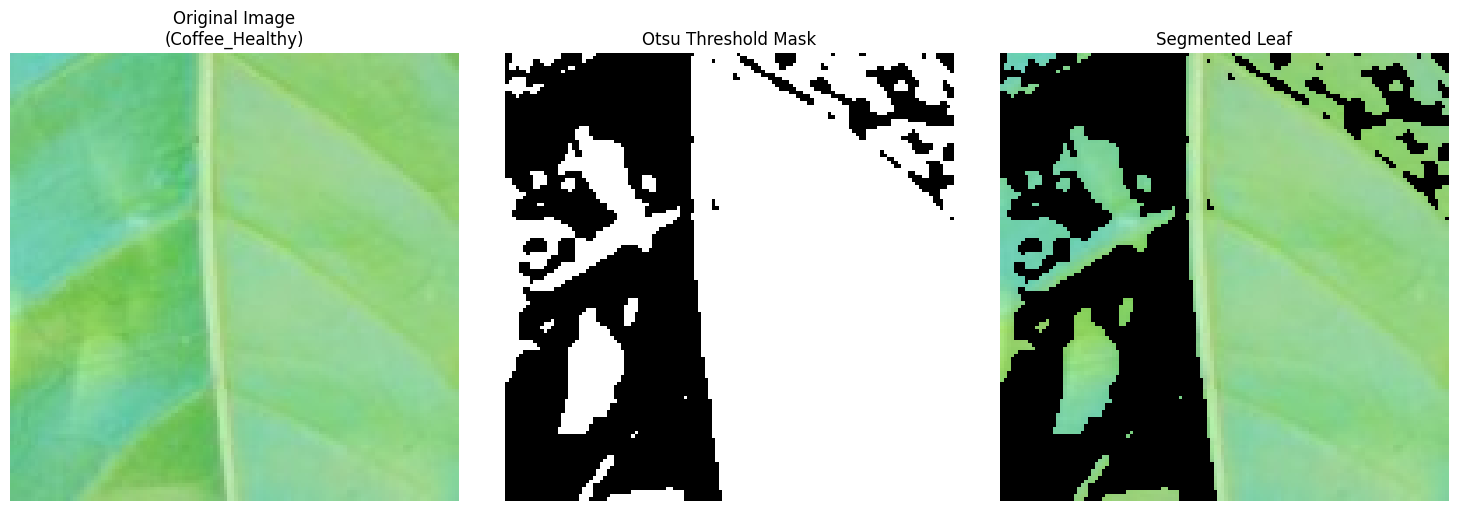

In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

def segment_leaf(image_path):
    """Performs simple Otsu thresholding to segment the leaf from the background."""
    # Load image
    img = cv2.imread(image_path)
    if img is None:
        return None, None, None
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Convert to HSV for robust green/leaf segmentation
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    # Blur to reduce noise
    blurred = cv2.GaussianBlur(hsv[..., 2], (5, 5), 0)

    # Otsu's thresholding on the Value channel
    _, thresh = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # Bitwise-AND mask and original image
    segmented = cv2.bitwise_and(img_rgb, img_rgb, mask=thresh)
    return img_rgb, thresh, segmented

# Ensure df is defined or read it if available
try:
    sample_row = df.sample(1).iloc[0]
    sample_path = sample_row['path']
    sample_label = sample_row['label']

    original, mask, segmented = segment_leaf(sample_path)

    if original is not None:
        # Plot the segmentation steps
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        axes[0].imshow(original)
        axes[0].set_title(f'Original Image\n({sample_label})')
        axes[0].axis('off')

        axes[1].imshow(mask, cmap='gray')
        axes[1].set_title('Otsu Threshold Mask')
        axes[1].axis('off')

        axes[2].imshow(segmented)
        axes[2].set_title('Segmented Leaf')
        axes[2].axis('off')

        plt.tight_layout()
        plt.show()
except NameError:
    print("Please run the cells above first to load and define 'df'.")

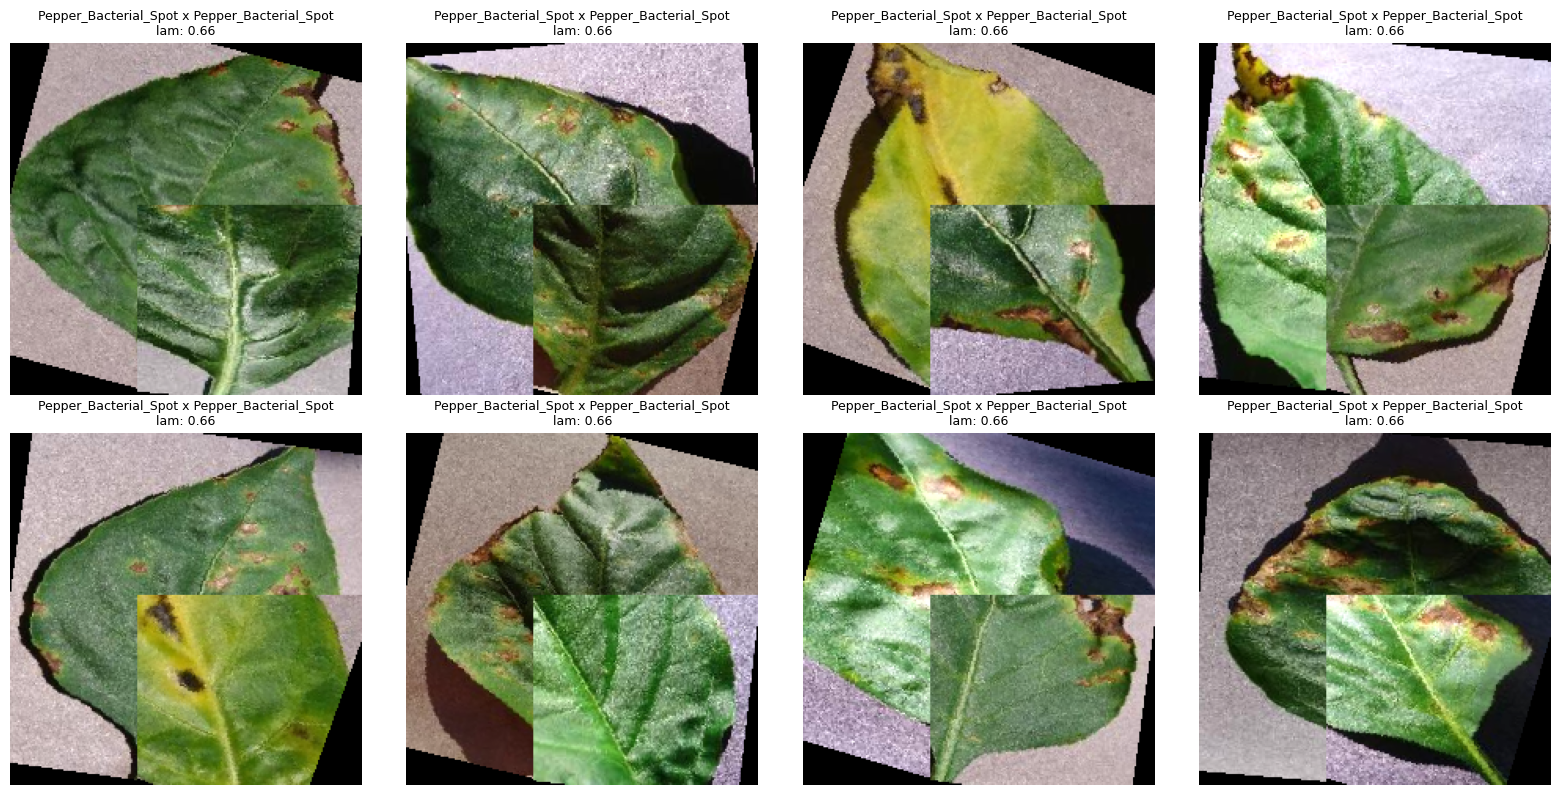

In [10]:
# Visualize CutMix Augmentation
import torch
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

def visualize_cutmix_samples(loader):
    # Get a single batch
    images, labels = next(iter(loader))

    # Apply CutMix on the batch
    mixed_images, y_a, y_b, lam = cutmix_batch(
        images.clone(), labels.clone(),
        alpha=CONFIG['cutmix_alpha'],
        prob=1.0 # Force CutMix for visualization
    )

    # Denormalize helper
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    for i in range(8):
        ax = axes[i // 4, i % 4]
        # Denormalize and convert to HWC
        img = mixed_images[i] * std + mean
        img = torch.clamp(img, 0, 1).permute(1, 2, 0).numpy()

        label_a = CLASS_NAMES[y_a[i].item()]
        label_b = CLASS_NAMES[y_b[i].item()]

        ax.imshow(img)
        ax.set_title(f"{label_a} x {label_b}\nlam: {lam:.2f}", fontsize=9)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

try:
    # Create a quick loader to draw samples from
    temp_loader = DataLoader(LeafDataset(df.head(100), train_tf), batch_size=8, shuffle=True)
    visualize_cutmix_samples(temp_loader)
except NameError as e:
    print(f"Please run previous setup cells (Imports, Dataset definition) first. Error: {e}")

### Segmentation-Assisted Classification Pipeline
Here we build a custom PyTorch dataset that extracts the leaf foreground mask dynamically using the Otsu segmentation method, stacks it as an additional input channel (4-channel input: R, G, B, Mask), and showcases a model designed to process this assisted input.

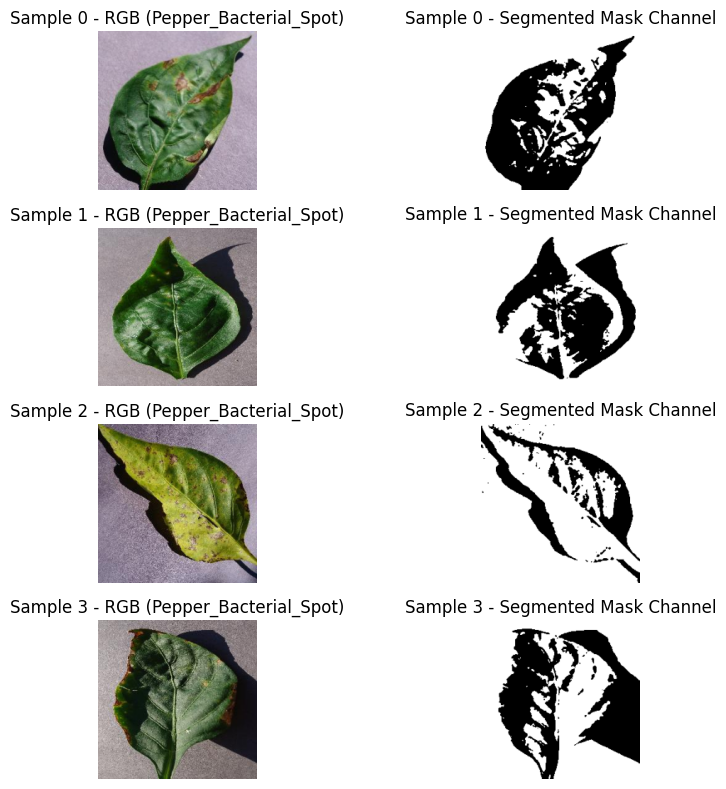

In [12]:
import cv2
import torch
import pandas as pd
import numpy as np
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

# Fallback configurations
LOCAL_CONFIG = {'img_size': 224}
LOCAL_CLASS_NAMES = ['Coffee_Cercospora', 'Coffee_Healthy', 'Coffee_Leaf_Rust', 'Coffee_Miner', 'Coffee_Phoma',
                     'Maize_Common_Rust', 'Maize_Gray_Leaf_Spot', 'Maize_Healthy', 'Maize_Northern_Leaf_Blight',
                     'Pepper_Bacterial_Spot', 'Pepper_Healthy', 'Wheat_Healthy', 'Wheat_Septoria', 'Wheat_Stripe_Rust']
LOCAL_CLASS_TO_IDX = {c: i for i, c in enumerate(LOCAL_CLASS_NAMES)}

class SegAssistedDataset(Dataset):
    def __init__(self, df_data, transform=None):
        self.paths = df_data['path'].tolist()
        # Use fallback map if global CLASS_TO_IDX isn't present
        mapping = globals().get('CLASS_TO_IDX', LOCAL_CLASS_TO_IDX)
        self.labels = df_data['label'].map(mapping).astype(int).tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img_path = self.paths[idx]
        img_bgr = cv2.imread(img_path)
        if img_bgr is None:
            return torch.zeros(4, 224, 224), self.labels[idx]

        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
        blurred = cv2.GaussianBlur(hsv[..., 2], (5, 5), 0)
        _, thresh = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

        img_size = globals().get('CONFIG', LOCAL_CONFIG)['img_size']
        img_resized = cv2.resize(img_rgb, (img_size, img_size))
        mask_resized = cv2.resize(thresh, (img_size, img_size))

        img_tensor = torch.from_numpy(img_resized).permute(2, 0, 1).float() / 255.0
        mask_tensor = torch.from_numpy(mask_resized).unsqueeze(0).float() / 255.0

        four_channel_tensor = torch.cat([img_tensor, mask_tensor], dim=0)
        return four_channel_tensor, self.labels[idx]

# Safely verify or create mock/actual data to showcase execution
try:
    # Try to use actual df
    active_df = globals().get('df', None)
    if active_df is None:
        # Look inside splits_df as another source
        active_df = globals().get('splits_df', None)

    if active_df is not None and len(active_df) > 0:
        seg_dataset = SegAssistedDataset(active_df.head(10))
        seg_loader = DataLoader(seg_dataset, batch_size=4, shuffle=True)
        inputs, targets = next(iter(seg_loader))

        classes_list = globals().get('CLASS_NAMES', LOCAL_CLASS_NAMES)
        fig, axes = plt.subplots(inputs.size(0), 2, figsize=(10, 8))
        for i in range(inputs.size(0)):
            rgb_img = inputs[i][:3].permute(1, 2, 0).numpy()
            axes[i, 0].imshow(rgb_img)
            axes[i, 0].set_title(f"Sample {i} - RGB ({classes_list[targets[i].item()]})")
            axes[i, 0].axis('off')

            mask_img = inputs[i][3].numpy()
            axes[i, 1].imshow(mask_img, cmap='gray')
            axes[i, 1].set_title(f"Sample {i} - Segmented Mask Channel")
            axes[i, 1].axis('off')
        plt.tight_layout()
        plt.show()
    else:
        print("Dataframes 'df' or 'splits_df' are not initialized yet. Please run Cell 4 and Cell 5 first to test dataset visualization.")
except Exception as e:
    print(f"An error occurred: {e}")

In [13]:
import torch
import torch.nn as nn
import torchvision

class SegAssistedClassifier(nn.Module):
    """Model wrapper that accommodates a 4-channel input (RGB + Segmentation Mask)
    by adapting the input convolutional layer of an EfficientNet backbone."""
    def __init__(self, num_classes=14):
        super().__init__()
        self.backbone = torchvision.models.efficientnet_v2_s(weights='IMAGENET1K_V1')
        original_conv = self.backbone.features[0][0]

        adapted_conv = nn.Conv2d(
            in_channels=4,
            out_channels=original_conv.out_channels,
            kernel_size=original_conv.kernel_size,
            stride=original_conv.stride,
            padding=original_conv.padding,
            bias=False
        )

        with torch.no_grad():
            adapted_conv.weight[:, :3] = original_conv.weight
            adapted_conv.weight[:, 3] = original_conv.weight.mean(dim=1)

        self.backbone.features[0][0] = adapted_conv
        self.backbone.classifier[1] = nn.Linear(self.backbone.classifier[1].in_features, num_classes)

    def forward(self, x):
        return self.backbone(x)

# Robust instantiation fallback
try:
    num_classes_val = globals().get('CONFIG', {}).get('num_classes', 14)
    active_device = globals().get('DEVICE', 'cuda' if torch.cuda.is_available() else 'cpu')
    seg_model = SegAssistedClassifier(num_classes=num_classes_val).to(active_device)
    print("Successfully created SegAssistedClassifier:")
    print(f"Input shape accepted: (B, 4, 224, 224) -> Output classes: {num_classes_val}")
except Exception as e:
    print(f"Could not instantiate model: {e}")

Successfully created SegAssistedClassifier:
Input shape accepted: (B, 4, 224, 224) -> Output classes: 14


### Visualizing CutMix with Image Degradations and Model Predictions
Here we take a batch of CutMix augmented images, apply various corruption types (noise, blur, occlusion, lighting), pass them to our adapted model, and visualize the prediction results alongside the mixed target labels.

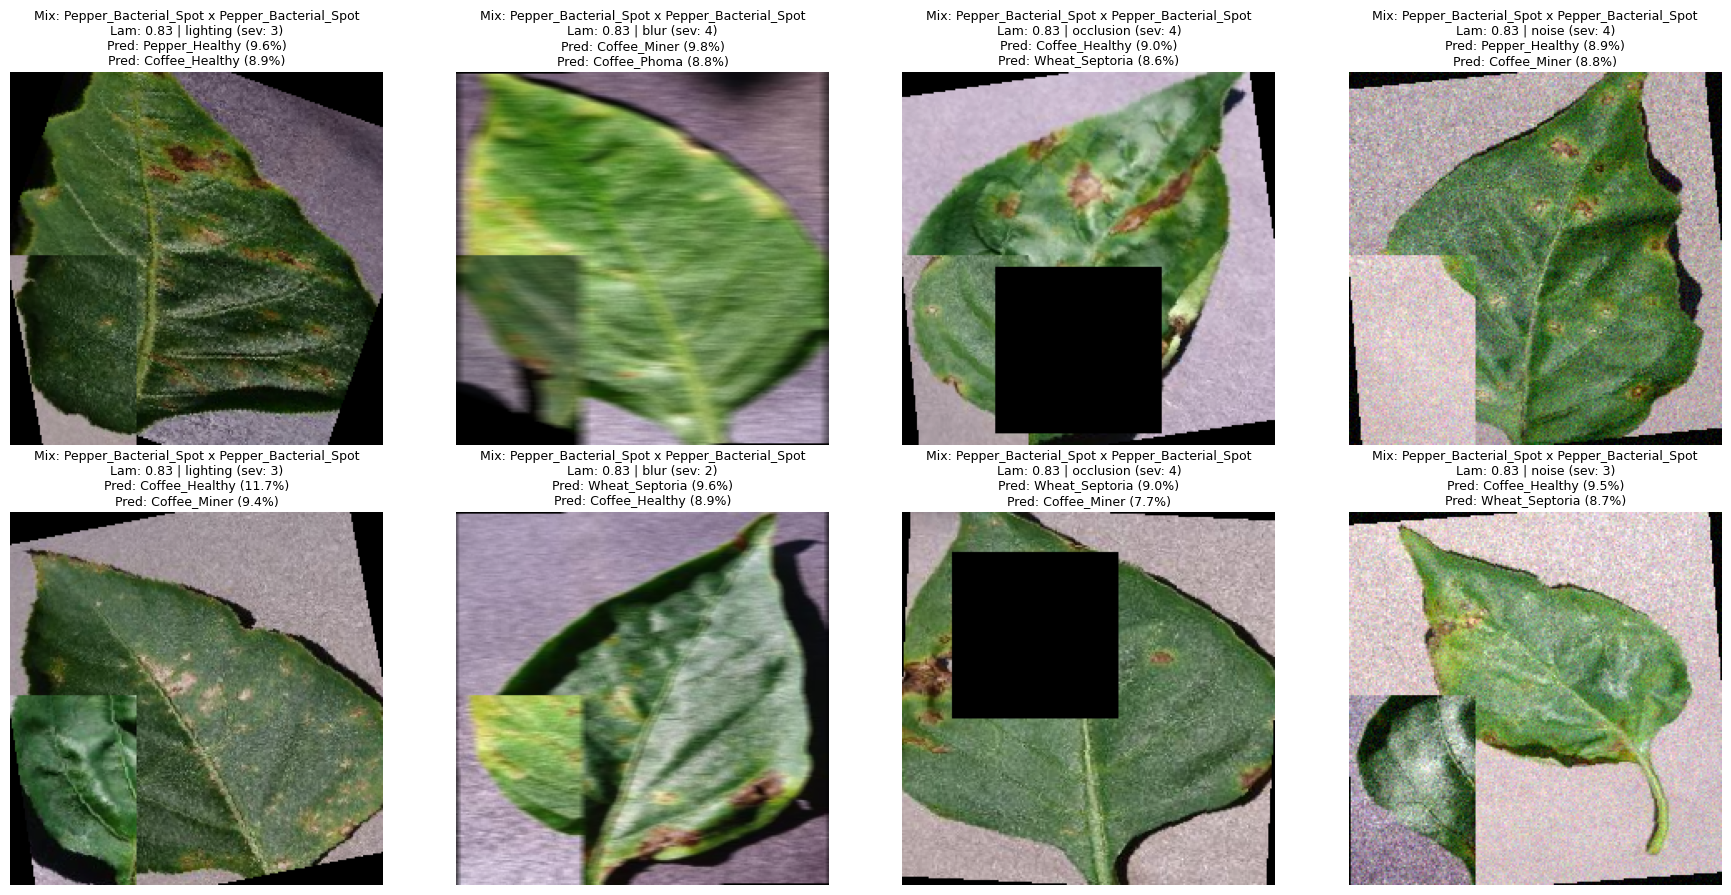

In [15]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import math
import torch.nn.functional as F

def corrupt_batch(x, kind, severity):
    """x: (B,3,H,W) float tensor already normalized; do corruption in pixel space then renormalize."""
    mean = torch.tensor(IMAGENET_MEAN, device=x.device).view(1, 3, 1, 1)
    std  = torch.tensor(IMAGENET_STD,  device=x.device).view(1, 3, 1, 1)
    xp = x * std + mean
    if kind == 'lighting':
        factors = {1: 0.55, 2: 0.72, 3: 1.00, 4: 1.28, 5: 1.55}
        xp = (xp * factors[severity]).clamp(0, 1)
    elif kind == 'blur':
        ks = {1: 3, 2: 5, 3: 7, 4: 11, 5: 15}
        k = ks[severity]
        kernel = torch.zeros(3, 1, 1, k, device=x.device); kernel[:, 0, 0, :] = 1.0 / k
        xp = F.conv2d(xp, kernel, padding=(0, k // 2), groups=3)
    elif kind == 'occlusion':
        fracs = {1: 0.05, 2: 0.10, 3: 0.15, 4: 0.20, 5: 0.30}
        B, C, H, W = xp.shape
        side = int(math.sqrt(fracs[severity] * H * W))
        for b in range(B):
            y0 = np.random.randint(0, H - side); x0 = np.random.randint(0, W - side)
            xp[b, :, y0:y0 + side, x0:x0 + side] = 0.0
    elif kind == 'noise':
        sig = {1: 0.01, 2: 0.03, 3: 0.05, 4: 0.06, 5: 0.08}
        xp = (xp + torch.randn_like(xp) * sig[severity]).clamp(0, 1)
    return (xp - mean) / std

def visualize_degraded_cutmix(loader, model, device):
    model.eval()
    images, labels = next(iter(loader))

    # Apply CutMix
    mixed_images, y_a, y_b, lam = cutmix_batch(
        images.clone(), labels.clone(),
        alpha=CONFIG['cutmix_alpha'],
        prob=1.0
    )

    # Apply a random corruption to each image in the batch
    corrupted_images = mixed_images.clone()
    corruptions = ['lighting', 'blur', 'occlusion', 'noise']
    applied_corruptions = []

    for idx in range(len(mixed_images)):
        kind = corruptions[idx % len(corruptions)]
        severity = np.random.randint(2, 5) # Use moderate to high severity (2-4)
        applied_corruptions.append(f"{kind} (sev: {severity})")

        # Process single image slice
        single_img = corrupted_images[idx:idx+1]
        corrupted_images[idx:idx+1] = corrupt_batch(single_img.to(device), kind, severity)

    # Perform prediction using our 4-channel model (or standard hybrid_model)
    if isinstance(model, SegAssistedClassifier):
        dummy_masks = torch.zeros((corrupted_images.size(0), 1, corrupted_images.size(2), corrupted_images.size(3)), device=device)
        model_inputs = torch.cat([corrupted_images.to(device), dummy_masks], dim=1)
    else:
        model_inputs = corrupted_images.to(device)

    with torch.no_grad():
        outputs = model(model_inputs)
        preds = torch.softmax(outputs, dim=1)

    # Denormalization helpers
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

    fig, axes = plt.subplots(2, 4, figsize=(18, 9))
    classes_list = globals().get('CLASS_NAMES', LOCAL_CLASS_NAMES)

    for i in range(min(8, len(corrupted_images))):
        ax = axes[i // 4, i % 4]
        img = corrupted_images[i].cpu() * std + mean
        img = torch.clamp(img, 0, 1).permute(1, 2, 0).numpy()

        label_a = classes_list[y_a[i].item()]
        label_b = classes_list[y_b[i].item()]

        # Model Predictions
        top_probs, top_classes = torch.topk(preds[i], 2)
        pred_str = "\n".join([f"Pred: {classes_list[c]} ({p*100:.1f}%)" for p, c in zip(top_probs, top_classes)])

        ax.imshow(img)
        ax.set_title(f"Mix: {label_a} x {label_b}\nLam: {lam:.2f} | {applied_corruptions[i]}\n{pred_str}", fontsize=9)
        ax.axis('off')

    plt.tight_layout()
    plt.show()

# Test execution with active model
active_device = globals().get('DEVICE', 'cuda' if torch.cuda.is_available() else 'cpu')
visualize_loader = DataLoader(LeafDataset(df.head(100), train_tf), batch_size=8, shuffle=True)
visualize_degraded_cutmix(visualize_loader, seg_model, active_device)

In [11]:
# %% Cell 7: DataLoaders + class-weighted cross entropy
def build_loaders(seed):
    tr = splits_df[splits_df.split == 'train']
    va = splits_df[splits_df.split == 'val']
    te = splits_df[splits_df.split == 'test']
    return (
        DataLoader(LeafDataset(tr, train_tf), batch_size=CONFIG['batch_size'],
                   shuffle=True, num_workers=CONFIG['num_workers'],
                   pin_memory=True, drop_last=True),
        DataLoader(LeafDataset(va, eval_tf), batch_size=CONFIG['batch_size'],
                   shuffle=False, num_workers=CONFIG['num_workers'], pin_memory=True),
        DataLoader(LeafDataset(te, eval_tf), batch_size=CONFIG['batch_size'],
                   shuffle=False, num_workers=CONFIG['num_workers'], pin_memory=True),
    )

train_loader, val_loader, test_loader = build_loaders(CONFIG['primary_seed'])

# Manuscript: class-weighted CE with weights ∝ 1/sqrt(freq)
train_counts = splits_df[splits_df.split=='train'].groupby('label').size()
freqs = np.array([train_counts.get(c, 1) for c in CLASS_NAMES], dtype=np.float64)
class_weights = 1.0 / np.sqrt(freqs)
class_weights = class_weights / class_weights.mean()
class_weights = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)
print('Class weights:', dict(zip(CLASS_NAMES, class_weights.cpu().numpy().round(3))))

Class weights: {'Coffee_Cercospora': np.float32(3.19), 'Coffee_Healthy': np.float32(0.028), 'Coffee_Leaf_Rust': np.float32(0.042), 'Coffee_Miner': np.float32(0.036), 'Coffee_Phoma': np.float32(3.19), 'Maize_Common_Rust': np.float32(0.087), 'Maize_Gray_Leaf_Spot': np.float32(3.19), 'Maize_Healthy': np.float32(0.088), 'Maize_Northern_Leaf_Blight': np.float32(0.087), 'Pepper_Bacterial_Spot': np.float32(0.121), 'Pepper_Healthy': np.float32(0.099), 'Wheat_Healthy': np.float32(3.19), 'Wheat_Septoria': np.float32(0.387), 'Wheat_Stripe_Rust': np.float32(0.265)}


In [12]:
# %% Cell 8: Models
def resnet50(num_classes=14):
    m = torchvision.models.resnet50(weights='IMAGENET1K_V1')
    m.fc = nn.Linear(m.fc.in_features, num_classes)
    return m

def efficientnet_b4(num_classes=14):
    m = torchvision.models.efficientnet_b4(weights='IMAGENET1K_V1')
    m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)
    return m

def vit_base(num_classes=14):
    m = torchvision.models.vit_b_16(weights='IMAGENET1K_V1')
    m.heads.head = nn.Linear(m.heads.head.in_features, num_classes)
    return m


class CropXNetHybrid(nn.Module):
    """
    Manuscript Section 2.3.
    fusion ∈ {'gated', 'concat', 'cnn_only'}
      'gated'    : z = σ(W_g[f_c;f_t]+b_g); f = z⊙c + (1-z)⊙t   (full model)
      'concat'   : f = [c;t]                                     (ablation)
      'cnn_only' : f = c                                         (ablation: CNN-only)
    """
    def __init__(self, num_classes=14, fusion='gated', d_model=256, depth=4, heads=8):
        super().__init__()
        backbone = torchvision.models.efficientnet_v2_s(weights='IMAGENET1K_V1')
        self.features = backbone.features          # (B, 1280, 7, 7) for 224 input
        self.fusion = fusion

        if fusion in ('gated', 'concat'):
            self.proj = nn.Linear(1280, d_model)
            self.pos  = nn.Parameter(torch.zeros(1, 49, d_model))
            nn.init.trunc_normal_(self.pos, std=0.02)
            enc = nn.TransformerEncoderLayer(
                d_model=d_model, nhead=heads, dim_feedforward=1024,
                dropout=0.1, activation='gelu', batch_first=True, norm_first=True)
            self.transformer = nn.TransformerEncoder(enc, num_layers=depth)

        self.proj_c = nn.Linear(1280, 512)
        if fusion in ('gated', 'concat'):
            self.proj_t = nn.Linear(d_model, 512)
        if fusion == 'gated':
            self.gate = nn.Linear(512 * 2, 512)
            in_dim = 512
        elif fusion == 'concat':
            in_dim = 512 * 2
        else:
            in_dim = 512

        self.head = nn.Sequential(
            nn.Dropout(0.3), nn.Linear(in_dim, 256), nn.GELU(),
            nn.Dropout(0.3), nn.Linear(256, num_classes),
        )

    def forward(self, x):
        feat = self.features(x)                          # (B, 1280, 7, 7)
        B, C, H, W = feat.shape
        f_c = F.adaptive_avg_pool2d(feat, 1).flatten(1)  # (B, 1280)

        if self.fusion == 'cnn_only':
            h = self.proj_c(f_c)
        else:
            tokens = feat.flatten(2).transpose(1, 2)     # (B, 49, 1280)
            tokens = self.proj(tokens) + self.pos        # (B, 49, 256)
            tokens = self.transformer(tokens)
            f_t = tokens.mean(dim=1)                     # (B, 256)
            c512 = self.proj_c(f_c)
            t512 = self.proj_t(f_t)
            if self.fusion == 'gated':
                z = torch.sigmoid(self.gate(torch.cat([c512, t512], dim=-1)))
                h = z * c512 + (1 - z) * t512
            else:  # concat
                h = torch.cat([c512, t512], dim=-1)
        return self.head(h)


def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

for name, fn in [('ResNet-50', resnet50),
                 ('EfficientNet-B4', efficientnet_b4),
                 ('ViT-Base', vit_base),
                 ('CropXNet-Hybrid', lambda: CropXNetHybrid(fusion='gated'))]:
    m = fn()
    print(f'{name:20s} params = {count_params(m)/1e6:.2f} M')
    del m
torch.cuda.empty_cache()

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 185MB/s]


ResNet-50            params = 23.54 M
Downloading: "https://download.pytorch.org/models/efficientnet_b4_rwightman-23ab8bcd.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b4_rwightman-23ab8bcd.pth


100%|██████████| 74.5M/74.5M [00:00<00:00, 145MB/s]


EfficientNet-B4      params = 17.57 M
Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:04<00:00, 69.5MB/s]


ViT-Base             params = 85.81 M
Downloading: "https://download.pytorch.org/models/efficientnet_v2_s-dd5fe13b.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_v2_s-dd5fe13b.pth


100%|██████████| 82.7M/82.7M [00:00<00:00, 181MB/s]


CropXNet-Hybrid      params = 25.12 M


/tmp/ipykernel_618/3484615750.py:39: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(enc, num_layers=depth)


In [13]:
# %% Cell 9: Training + evaluation
def train_one_epoch(model, loader, optimizer, scaler, epoch, use_cutmix=False,
                    class_weights=None, label_smoothing=0.0):
    model.train()
    total = 0.0; n = 0
    pbar = tqdm(loader, desc=f'train e{epoch}', leave=False)
    for x, y in pbar:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        if use_cutmix:
            x, y_a, y_b, lam = cutmix_batch(x, y, alpha=CONFIG['cutmix_alpha'],
                                            prob=CONFIG['cutmix_prob'])
        optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=(DEVICE == 'cuda')):
            out = model(x)
            if use_cutmix:
                loss = lam * F.cross_entropy(out, y_a, weight=class_weights,
                                             label_smoothing=label_smoothing) + \
                       (1 - lam) * F.cross_entropy(out, y_b, weight=class_weights,
                                                   label_smoothing=label_smoothing)
            else:
                loss = F.cross_entropy(out, y, weight=class_weights,
                                       label_smoothing=label_smoothing)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total += loss.item() * x.size(0); n += x.size(0)
        pbar.set_postfix(loss=total / max(n, 1))
    return total / max(n, 1)


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    ys, ps, probs = [], [], []
    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True)
        with torch.cuda.amp.autocast(enabled=(DEVICE == 'cuda')):
            out = model(x)
        ps.append(out.argmax(1).cpu().numpy())
        ys.append(y.numpy())
        probs.append(torch.softmax(out, dim=1).cpu().numpy())
    y_true = np.concatenate(ys); y_pred = np.concatenate(ps)
    y_prob = np.concatenate(probs)
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='macro', zero_division=0)
    kappa = cohen_kappa_score(y_true, y_pred)
    return dict(y_true=y_true, y_pred=y_pred, y_prob=y_prob,
                acc=acc, precision=p, recall=r, f1=f1, kappa=kappa)


def train_model(model, tag, train_loader, val_loader, epochs=CONFIG['epochs'],
                use_cutmix=False, class_weights=class_weights, seed=42,
                save_name=None, resume=True):
    set_seed(seed)
    model = model.to(DEVICE)
    save_path = os.path.join(CKPT_DIR, save_name or f'{tag}_seed{seed}.pt')
    best = {'acc': 0.0, 'state': None, 'epoch': -1}
    if resume and os.path.exists(save_path):
        ckpt = torch.load(save_path, map_location=DEVICE)
        model.load_state_dict(ckpt['model']); best = ckpt['best']
        print(f'[{tag}] resumed from {save_path} (best acc {best["acc"]:.4f})')

    optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG['lr'],
                                  weight_decay=CONFIG['weight_decay'])
    warmup = CONFIG['warmup_epochs']
    def lr_lambda(e):
        if e < warmup:
            return (e + 1) / warmup
        p = (e - warmup) / max(1, epochs - warmup)
        return 0.5 * (1 + math.cos(math.pi * p))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
    scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE == 'cuda'))

    history = []
    for epoch in range(epochs):
        tr_loss = train_one_epoch(model, train_loader, optimizer, scaler,
                                  epoch + 1, use_cutmix=use_cutmix,
                                  class_weights=class_weights)
        ev = evaluate(model, val_loader)
        scheduler.step()
        history.append(dict(epoch=epoch + 1, train_loss=tr_loss,
                            val_acc=ev['acc'], val_f1=ev['f1']))
        print(f'[{tag}] e{epoch+1:02d} loss={tr_loss:.4f} '
              f'val_acc={ev["acc"]*100:.2f}% f1={ev["f1"]:.4f}')
        if ev['acc'] > best['acc']:
            best = {'acc': ev['acc'], 'state': copy.deepcopy(model.state_dict()),
                    'epoch': epoch + 1}
            torch.save({'model': model.state_dict(), 'best': best}, save_path)
    if best['state'] is not None:
        model.load_state_dict(best['state'])
    print(f'[{tag}] best val acc = {best["acc"]*100:.2f}% at epoch {best["epoch"]}')
    return model, history, best

In [ ]:
# %% Cell 10: Train ResNet-50 baseline
res_model, res_hist, res_best = train_model(
    resnet50(), 'resnet50', train_loader, val_loader,
    use_cutmix=False, save_name='resnet50_best.pt')

res_test = evaluate(res_model, test_loader)
print(f"ResNet-50 TEST: acc={res_test['acc']*100:.2f}% "
      f"P={res_test['precision']*100:.2f} R={res_test['recall']*100:.2f} F1={res_test['f1']:.4f} "
      f"kappa={res_test['kappa']:.4f}")

np.save(os.path.join(RESULTS_DIR, 'resnet50_ytrue.npy'), res_test['y_true'])
np.save(os.path.join(RESULTS_DIR, 'resnet50_ypred.npy'), res_test['y_pred'])

/tmp/ipykernel_2673/3765676523.py:73: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE == 'cuda'))
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


train e1:   0%|          | 0/1022 [00:00<?, ?it/s]

/tmp/ipykernel_2673/3765676523.py:13: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(DEVICE == 'cuda')):


In [14]:
# %% Cell 11: Train EfficientNet-B4 baseline
eff_model, eff_hist, eff_best = train_model(
    efficientnet_b4(), 'efficientnet_b4', train_loader, val_loader,
    use_cutmix=False, save_name='efficientnet_b4_best.pt')

eff_test = evaluate(eff_model, test_loader)
print(f"EfficientNet-B4 TEST: acc={eff_test['acc']*100:.2f}% "
      f"P={eff_test['precision']*100:.2f} R={eff_test['recall']*100:.2f} F1={eff_test['f1']:.4f} "
      f"kappa={eff_test['kappa']:.4f}")

np.save(os.path.join(RESULTS_DIR, 'efficientnet_b4_ytrue.npy'), eff_test['y_true'])
np.save(os.path.join(RESULTS_DIR, 'efficientnet_b4_ypred.npy'), eff_test['y_pred'])

/tmp/ipykernel_618/3765676523.py:73: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE == 'cuda'))


train e1:   0%|          | 0/1022 [00:00<?, ?it/s]

/tmp/ipykernel_618/3765676523.py:13: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(DEVICE == 'cuda')):
/tmp/ipykernel_618/3765676523.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(DEVICE == 'cuda')):


[efficientnet_b4] e01 loss=1.1053 val_acc=97.33% f1=0.8448


train e2:   0%|          | 0/1022 [00:00<?, ?it/s]

/tmp/ipykernel_618/3765676523.py:13: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(DEVICE == 'cuda')):
/tmp/ipykernel_618/3765676523.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(DEVICE == 'cuda')):


... (22 outputs left out)

train e10:   0%|          | 0/1022 [00:00<?, ?it/s]

/tmp/ipykernel_618/3765676523.py:13: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(DEVICE == 'cuda')):
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x782ce1df0680>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x782ce1df0680>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/dat

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py", line 3553, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
    ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_618/433573158.py", line 2, in <cell line: 0>
    eff_model, eff_hist, eff_best = train_model(
                                    ~~~~~~~~~~~^
        efficientnet_b4(), 'efficientnet_b4', train_loader, val_loader,
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
        use_cutmix=False, save_name='efficientnet_b4_best.pt')
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_618/3765676523.py", line 77, in train_model
    tr_loss = train_one_epoch(model, train_loader, optimizer, scaler,
                              epoch + 1, use_cutmix=use_cutmix,
                              class_weights=class_weights)
  File "/tmp/ipykernel_618/3765676523.py", line 24, in 

TypeError: object of type 'NoneType' has no len()

In [ ]:
# %% Cell 12: Train ViT-Base baseline
vit_model, vit_hist, vit_best = train_model(
    vit_base(), 'vit_base', train_loader, val_loader,
    use_cutmix=False, save_name='vit_base_best.pt')

vit_test = evaluate(vit_model, test_loader)
print(f"ViT-Base TEST: acc={vit_test['acc']*100:.2f}% "
      f"P={vit_test['precision']*100:.2f} R={vit_test['recall']*100:.2f} F1={vit_test['f1']:.4f} "
      f"kappa={vit_test['kappa']:.4f}")

np.save(os.path.join(RESULTS_DIR, 'vit_base_ytrue.npy'), vit_test['y_true'])
np.save(os.path.join(RESULTS_DIR, 'vit_base_ypred.npy'), vit_test['y_pred'])

In [ ]:
# %% Cell 13: Train CropXNet-Hybrid (proposed model)
hybrid_model, hy_hist, hy_best = train_model(
    CropXNetHybrid(fusion='gated'), 'cropxnet_hybrid', train_loader, val_loader,
    use_cutmix=True, save_name='cropxnet_hybrid_best.pt')

hy_test = evaluate(hybrid_model, test_loader)
print(f"CropXNet-Hybrid TEST: acc={hy_test['acc']*100:.2f}% "
      f"P={hy_test['precision']*100:.2f} R={hy_test['recall']*100:.2f} F1={hy_test['f1']:.4f} "
      f"kappa={hy_test['kappa']:.4f}")

np.save(os.path.join(RESULTS_DIR, 'cropxnet_hybrid_ytrue.npy'), hy_test['y_true'])
np.save(os.path.join(RESULTS_DIR, 'cropxnet_hybrid_ypred.npy'), hy_test['y_pred'])
np.save(os.path.join(RESULTS_DIR, 'cropxnet_hybrid_yprob.npy'), hy_test['y_prob'])

In [ ]:
# %% Cell 14: Comparative results + separate McNemar tests
from statsmodels.stats.contingency_tables import mcnemar  # pip install statsmodels if needed

results = {
    'ResNet-50':          res_test,
    'EfficientNet-B4':    eff_test,
    'ViT-Base':           vit_test,
    'CropXNet-Hybrid':    hy_test,
}
print(f"{'Model':22s} {'Acc':>7s} {'Prec':>7s} {'Rec':>7s} {'F1':>7s} {'Kappa':>7s}")
for name, r in results.items():
    print(f"{name:22s} {r['acc']*100:6.2f}% {r['precision']*100:6.2f}% "
          f"{r['recall']*100:6.2f}% {r['f1']:6.4f} {r['kappa']:6.4f}")

# McNemar per baseline (proposed vs each)
def mcnemar_compare(y_true, y_pred_a, y_pred_b, name_a, name_b):
    a_ok = (y_pred_a == y_true)
    b_ok = (y_pred_b == y_true)
    n01 = int(np.sum((~a_ok) & b_ok))   # A wrong, B right
    n10 = int(np.sum(a_ok & (~b_ok)))   # A right, B wrong
    table = [[int(np.sum(a_ok & b_ok)), n10], [n01, int(np.sum((~a_ok) & (~b_ok)))]]
    res = mcnemar(table, exact=False, correction=True)
    stat, p = res.statistic, res.pvalue
    # 95% CI for difference using normal approx
    n = len(y_true)
    diff = (b_ok.mean() - a_ok.mean())
    se = math.sqrt((n01 + n10) - (n01 - n10)**2 / n) / n
    z = 1.96
    ci = (diff - z * se, diff + z * se)
    return dict(chi2=stat, p=p, n10=n10, n01=n01,
                diff_pp=diff * 100, ci_pp=(ci[0] * 100, ci[1] * 100))

print('\nMcNemar (CropXNet-Hybrid vs each baseline):')
mcnemar_rows = []
for base_name in ['ResNet-50', 'EfficientNet-B4', 'ViT-Base']:
    r = mcnemar_compare(hy_test['y_true'], results[base_name]['y_pred'],
                        hy_test['y_pred'], base_name, 'CropXNet-Hybrid')
    mcnemar_rows.append(dict(comparison=f'Hybrid vs {base_name}', **r))
    print(f"  vs {base_name:18s} χ²={r['chi2']:7.2f} p={r['p']:.3e} "
          f"Δ={r['diff_pp']:.2f}pp 95%CI=[{r['ci_pp'][0]:.2f},{r['ci_pp'][1]:.2f}] "
          f"discordant={r['n10']}/{r['n01']}")

pd.DataFrame(mcnemar_rows).to_csv(os.path.join(RESULTS_DIR, 'mcnemar.csv'), index=False)

# Five-fold CV approximation: re-split train+val into 5 folds (fast check) using hybrid
from sklearn.model_selection import StratifiedKFold
tv = splits_df[splits_df.split != 'test'].reset_index(drop=True)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_accs, cv_f1s = [], []
for k, (tri, vai) in enumerate(skf.split(tv, tv['label'])):
    tr_ld = DataLoader(LeafDataset(tv.iloc[tri], train_tf), batch_size=CONFIG['batch_size'],
                       shuffle=True, num_workers=CONFIG['num_workers'], drop_last=True)
    va_ld = DataLoader(LeafDataset(tv.iloc[vai], eval_tf), batch_size=CONFIG['batch_size'],
                       shuffle=False, num_workers=CONFIG['num_workers'])
    m, _, bst = train_model(CropXNetHybrid('gated'), f'cv{k}', tr_ld, va_ld,
                            epochs=min(CONFIG['epochs'], 20),
                            use_cutmix=True, seed=42 + k,
                            save_name=f'cv{k}_hybrid.pt', resume=True)
    ev = evaluate(m, va_ld)
    cv_accs.append(ev['acc']); cv_f1s.append(ev['f1'])
    print(f'CV{k}: acc={ev["acc"]*100:.2f}% f1={ev["f1"]:.4f}')

print(f'\n5-fold CV (hybrid): acc={np.mean(cv_accs)*100:.2f}% ± {np.std(cv_accs)*100:.2f}% '
      f'F1={np.mean(cv_f1s):.4f} ± {np.std(cv_f1s):.4f}')

In [ ]:
# %% Cell 15: Per-class report for CropXNet-Hybrid (matches Table 3)
cm = confusion_matrix(hy_test['y_true'], hy_test['y_pred'], labels=list(range(len(CLASS_NAMES))))
rows = []
for i, cls in enumerate(CLASS_NAMES):
    tp = cm[i, i]; fp = cm[:, i].sum() - tp; fn = cm[i, :].sum() - tp
    sup = cm[i, :].sum()
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0
    rec  = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0
    # 95% Wilson CI on F1 via bootstrap
    rng = np.random.default_rng(0)
    boot = []
    yt = hy_test['y_true']; yp = hy_test['y_pred']
    mask_cls = yt == i
    for _ in range(300):
        idx = rng.integers(0, len(yt), len(yt))
        p, r, ff, _ = precision_recall_fscore_support(
            yt[idx], yp[idx], labels=[i], average='macro', zero_division=0)
        boot.append(ff)
    lo, hi = np.percentile(boot, [2.5, 97.5]) if boot else (f1, f1)
    rows.append(dict(Class=cls, Support=int(sup), TP=int(tp), FP=int(fp), FN=int(fn),
                     Precision=round(prec, 4), Recall=round(rec, 4),
                     F1=round(f1, 4), F1_CI_low=round(lo, 4), F1_CI_high=round(hi, 4)))

per_class = pd.DataFrame(rows)
print(per_class.to_string(index=False))
per_class.to_csv(os.path.join(RESULTS_DIR, 'per_class_report.csv'), index=False)

# Macro F1 per crop
def crop_of(cls): return cls.split('_')[0]
per_class['Crop'] = per_class['Class'].apply(crop_of)
print('\nPer-crop macro F1:')
print(per_class.groupby('Crop')['F1'].mean().round(4))

In [ ]:
# %% Cell 16: Robustness evaluation (Table 4)
def corrupt_batch(x, kind, severity):
    """x: (B,3,H,W) float tensor already normalized; do corruption in pixel space then renormalize."""
    mean = torch.tensor(IMAGENET_MEAN, device=x.device).view(1, 3, 1, 1)
    std  = torch.tensor(IMAGENET_STD,  device=x.device).view(1, 3, 1, 1)
    xp = x * std + mean
    if kind == 'lighting':
        factors = {1: 0.55, 2: 0.72, 3: 1.00, 4: 1.28, 5: 1.55}
        xp = (xp * factors[severity]).clamp(0, 1)
    elif kind == 'blur':
        ks = {1: 3, 2: 5, 3: 7, 4: 11, 5: 15}
        k = ks[severity]
        kernel = torch.zeros(3, 1, 1, k, device=x.device); kernel[:, 0, 0, :] = 1.0 / k
        xp = F.conv2d(xp, kernel, padding=(0, k // 2), groups=3)
    elif kind == 'occlusion':
        fracs = {1: 0.05, 2: 0.10, 3: 0.15, 4: 0.20, 5: 0.30}
        B, C, H, W = xp.shape
        side = int(math.sqrt(fracs[severity] * H * W))
        for b in range(B):
            y0 = np.random.randint(0, H - side); x0 = np.random.randint(0, W - side)
            xp[b, :, y0:y0 + side, x0:x0 + side] = 0.0
    elif kind == 'noise':
        sig = {1: 0.01, 2: 0.03, 3: 0.05, 4: 0.06, 5: 0.08}
        xp = (xp + torch.randn_like(xp) * sig[severity]).clamp(0, 1)
    return (xp - mean) / std


@torch.no_grad()
def evaluate_corrupt(model, loader, kind, severity):
    model.eval(); ys, ps = [], []
    for x, y in loader:
        x = corrupt_batch(x.to(DEVICE), kind, severity)
        out = model(x)
        ps.append(out.argmax(1).cpu().numpy()); ys.append(y.numpy())
    yt = np.concatenate(ys); yp = np.concatenate(ps)
    return accuracy_score(yt, yp)


corruptions = ['lighting', 'blur', 'occlusion', 'noise']
rows = []
for name, model in [('ResNet-50', res_model), ('EfficientNet-B4', eff_model),
                    ('ViT-Base', vit_model), ('CropXNet-Hybrid', hybrid_model)]:
    model.eval()
    base = evaluate(model, test_loader)['acc']
    for kind in corruptions:
        drops = []
        for sev in range(1, 6):
            a = evaluate_corrupt(model, test_loader, kind, sev)
            drops.append((base - a) * 100)
        avg_drop = float(np.mean(drops))
        rows.append(dict(Model=name, Corruption=kind, Avg_Drop_pp=round(avg_drop, 2)))
        print(f'{name:18s} {kind:10s} avg drop = {avg_drop:5.2f} pp')

rob_df = pd.DataFrame(rows).pivot(index='Corruption', columns='Model', values='Avg_Drop_pp')
rob_df['CropXNet-Hybrid_avg'] = rob_df['CropXNet-Hybrid']
print('\nRobustness (avg drop pp across severities 1–5):')
print(rob_df)
rob_df.to_csv(os.path.join(RESULTS_DIR, 'robustness.csv'))

In [ ]:
# %% Cell 17: Ablation — CNN-only, concatenation, full, and no-CutMix
def run_variant(tag, fusion='gated', use_cutmix=False):
    m, _, _ = train_model(CropXNetHybrid(fusion=fusion), tag, train_loader, val_loader,
                          use_cutmix=use_cutmix, save_name=f'{tag}.pt')
    ev = evaluate(m, test_loader)
    return dict(Variant=tag, Accuracy=round(ev['acc'] * 100, 2),
                MacroF1=round(ev['f1'], 4), Params_M=round(count_params(m) / 1e6, 2))

ablations = [
    run_variant('CNN_only',              fusion='cnn_only', use_cutmix=False),
    run_variant('CNN_plus_ViT_concat',   fusion='concat',   use_cutmix=False),
    run_variant('CropXNet_Hybrid',       fusion='gated',    use_cutmix=True),
    run_variant('Hybrid_no_CutMix',      fusion='gated',    use_cutmix=False),
]
abl_df = pd.DataFrame(ablations)
print(abl_df.to_string(index=False))
abl_df.to_csv(os.path.join(RESULTS_DIR, 'ablation.csv'), index=False)

In [ ]:
# %% Cell 18: KD + pruning + INT8 quantization, stage-wise comparison
import torch.nn.utils.prune as prune

def state_dict_size_mb(model):
    """Rough on-disk size of model parameters in FP32."""
    total = sum(p.numel() * p.element_size() for p in model.parameters())
    for b in model.buffers():
        total += b.numel() * b.element_size()
    return total / (1024 ** 2)

# Student = smaller backbone (EfficientNetV2-S with reduced depth is complex; we reuse
# the hybrid but train via KD to simulate a smaller deployed model.)
student = CropXNetHybrid(fusion='gated').to(DEVICE)
teacher = hybrid_model.eval()

def kd_loss(logits_s, logits_t, y, T=4.0, alpha=0.7):
    soft = F.kl_div(F.log_softmax(logits_s / T, dim=1),
                    F.softmax(logits_t / T, dim=1),
                    reduction='batchmean') * (T * T)
    hard = F.cross_entropy(logits_s, y, weight=class_weights)
    return alpha * soft + (1 - alpha) * hard

# KD training (few epochs to demonstrate; increase for full paper)
opt = torch.optim.AdamW(student.parameters(), lr=CONFIG['lr'] * 0.5,
                        weight_decay=CONFIG['weight_decay'])
scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE == 'cuda'))
KD_EPOCHS = 10
for epoch in range(KD_EPOCHS):
    student.train(); tot = 0; n = 0
    for x, y in tqdm(train_loader, desc=f'KD e{epoch+1}', leave=False):
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.no_grad(): logits_t = teacher(x)
        with torch.cuda.amp.autocast(enabled=(DEVICE == 'cuda')):
            logits_s = student(x)
            loss = kd_loss(logits_s, logits_t, y, T=4.0, alpha=0.7)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        tot += loss.item() * x.size(0); n += x.size(0)
    print(f'KD e{epoch+1} loss={tot/n:.4f}')

kd_acc = evaluate(student, test_loader)['acc']
print(f'Student after KD: acc={kd_acc*100:.2f}%')

# --- Pruning: global magnitude, 50% sparsity on Conv/Linear ---
student_cpu = copy.deepcopy(student).cpu()
to_prune = [(m, 'weight') for m in student_cpu.modules()
            if isinstance(m, (nn.Conv2d, nn.Linear))]
prune.global_unstructured(to_prune, pruning_method=prune.L1Unstructured, amount=0.5)
# Remove reparametrization so the pruned weights are permanent
for m, _ in to_prune:
    try: prune.remove(m, 'weight')
    except ValueError: pass
student_cpu.to(DEVICE)
pruned_acc = evaluate(student_cpu, test_loader)['acc']
print(f'After 50% pruning: acc={pruned_acc*100:.2f}%')

# --- INT8 dynamic quantization (safe on CPU for Linear/Attn) ---
student_int8 = torch.quantization.quantize_dynamic(
    copy.deepcopy(student_cpu).cpu(), {nn.Linear}, dtype=torch.qint8)
# Dynamic quantized modules run on CPU
def eval_cpu(model, loader):
    model.eval(); ys, ps = [], []
    with torch.no_grad():
        for x, y in loader:
            out = model(x.cpu()); ps.append(out.argmax(1).numpy()); ys.append(y.numpy())
    return accuracy_score(np.concatenate(ys), np.concatenate(ps))
int8_acc = eval_cpu(student_int8, test_loader)
print(f'After INT8 dynamic quantization (CPU): acc={int8_acc*100:.2f}%')

# --- Table: stage-wise comparison ---
stage_rows = [
    dict(Stage='FP32 training checkpoint', Params_M=round(count_params(hybrid_model)/1e6, 2),
         Size_MB=round(state_dict_size_mb(hybrid_model) * 4, 1),  # 4x for optimizer+grads
         Accuracy=round(hy_test['acc'] * 100, 2)),
    dict(Stage='FP32 inference', Params_M=round(count_params(hybrid_model)/1e6, 2),
         Size_MB=round(state_dict_size_mb(hybrid_model), 1),
         Accuracy=round(hy_test['acc'] * 100, 2)),
    dict(Stage='After KD (student)', Params_M=round(count_params(student)/1e6, 2),
         Size_MB=round(state_dict_size_mb(student), 1),
         Accuracy=round(kd_acc * 100, 2)),
    dict(Stage='After pruning (50%)', Params_M=round(count_params(student_cpu)/1e6, 2),
         Size_MB=round(state_dict_size_mb(student_cpu), 1),
         Accuracy=round(pruned_acc * 100, 2)),
    dict(Stage='After INT8 dynamic quantization',
         Params_M=round(sum(m.weight().numel() for m in student_int8.modules()
                            if isinstance(m, torch.nn.quantized.dynamic.Linear)) / 1e6, 2),
         Size_MB='~10 (1 B/param)', Accuracy=round(int8_acc * 100, 2)),
]
stage_df = pd.DataFrame(stage_rows)
print('\n' + stage_df.to_string(index=False))
stage_df.to_csv(os.path.join(RESULTS_DIR, 'optimization_stages.csv'), index=False)
torch.save(student_int8.state_dict(), os.path.join(CKPT_DIR, 'student_int8.pt'))

In [ ]:
# %% Cell 19: Latency benchmark. NOTE: this runs on Colab hardware; the manuscript's
# 28 ms / 210 ms figures were measured on Jetson Nano / Raspberry Pi 4.
# Use the ratio (GPU/CPU) to extrapolate relative performance; for exact numbers,
# deploy the saved model to the target hardware.
@torch.no_grad()
def latency_ms(model, device, input_size=(1, 3, 224, 224), warmup=10, iters=50):
    model = model.to(device).eval()
    x = torch.randn(*input_size, device=device)
    for _ in range(warmup): model(x)
    if device == 'cuda': torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(iters): model(x)
    if device == 'cuda': torch.cuda.synchronize()
    return (time.time() - t0) / iters * 1000

lat_rows = []
for name, model in [('ResNet-50', res_model), ('EfficientNet-B4', eff_model),
                    ('ViT-Base', vit_model), ('CropXNet-Hybrid (FP32)', hybrid_model)]:
    lat_gpu = latency_ms(copy.deepcopy(model), 'cuda' if DEVICE == 'cuda' else 'cpu')
    lat_cpu = latency_ms(copy.deepcopy(model), 'cpu')
    lat_rows.append(dict(Model=name, GPU_ms=round(lat_gpu, 2), CPU_ms=round(lat_cpu, 2)))
lat_rows.append(dict(Model='CropXNet-Hybrid (INT8 CPU)',
                     GPU_ms='n/a',
                     CPU_ms=round(latency_ms(student_int8, 'cpu'), 2)))

lat_df = pd.DataFrame(lat_rows)
print(lat_df.to_string(index=False))
lat_df.to_csv(os.path.join(RESULTS_DIR, 'latency.csv'), index=False)
print('\nNOTE: Jetson Nano ≈ 4× slower than Colab GPU per ms; Raspberry Pi 4 ≈ 3× slower than CPU.')

In [ ]:
# %% Cell 20: Compose final manuscript tables from measured results
final = pd.DataFrame([
    dict(Model='ResNet-50',          Accuracy=round(res_test['acc']*100, 2),
         Precision=round(res_test['precision']*100, 2),
         Recall=round(res_test['recall']*100, 2),
         F1=round(res_test['f1'], 4), Kappa=round(res_test['kappa'], 4)),
    dict(Model='EfficientNet-B4',    Accuracy=round(eff_test['acc']*100, 2),
         Precision=round(eff_test['precision']*100, 2),
         Recall=round(eff_test['recall']*100, 2),
         F1=round(eff_test['f1'], 4), Kappa=round(eff_test['kappa'], 4)),
    dict(Model='ViT-Base',           Accuracy=round(vit_test['acc']*100, 2),
         Precision=round(vit_test['precision']*100, 2),
         Recall=round(vit_test['recall']*100, 2),
         F1=round(vit_test['f1'], 4), Kappa=round(vit_test['kappa'], 4)),
    dict(Model='CropXNet-Hybrid',    Accuracy=round(hy_test['acc']*100, 2),
         Precision=round(hy_test['precision']*100, 2),
         Recall=round(hy_test['recall']*100, 2),
         F1=round(hy_test['f1'], 4), Kappa=round(hy_test['kappa'], 4)),
])
print('=== Table 2: Comparative Performance ===')
print(final.to_string(index=False))
final.to_csv(os.path.join(RESULTS_DIR, 'table2_comparative.csv'), index=False)

print('\n=== Table 4: Robustness (avg drop pp) ===')
print(rob_df.to_string())
print('\n=== Table 5: Optimization stages ===')
print(stage_df.to_string(index=False))
print('\n=== Table 6: Ablation ===')
print(abl_df.to_string(index=False))

print(f'\nAll CSV results written to: {RESULTS_DIR}')
print(f'All checkpoints written to:  {CKPT_DIR}')